In [81]:
import pandas as pd
df = pd.read_csv("data/Churn_Modelling.csv")

In [82]:
df.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [83]:
df.shape

(10000, 14)

In [84]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [86]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [87]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [88]:
df["Geography"].value_counts()


Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [89]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [92]:
df.nunique()

RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

In [93]:
X = df.drop(columns=["RowNumber","CustomerId","Surname","Exited"])
y =df["Exited"]
print(X.shape)
print(y.shape)

(10000, 10)
(10000,)


In [94]:
print(X.dtypes)

CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
dtype: object


In [95]:
print(X["Geography"].unique())
print(X["Gender"].unique())

<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
<StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [96]:
# Binary mapping because there are only two categories -
X["Gender"] = X["Gender"].map(
    {
        "Female": 0, "Male" : 1
    }
)

# one-hot encoding 
X = pd.get_dummies(X,columns = ["Geography"], dtype =int)


print(X.head())
print(X.dtypes)

   CreditScore  Gender  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619       0   42       2       0.00              1          1   
1          608       0   41       1   83807.86              1          0   
2          502       0   42       8  159660.80              3          1   
3          699       0   39       1       0.00              2          0   
4          850       0   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_France  Geography_Germany  \
0               1        101348.88                 1                  0   
1               1        112542.58                 0                  0   
2               0        113931.57                 1                  0   
3               0         93826.63                 1                  0   
4               1         79084.10                 0                  0   

   Geography_Spain  
0                0  
1                1  
2                0  
3       

In [97]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state = 42,stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 12)
(2000, 12)
(8000,)
(2000,)


In [98]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Exited
0    0.79625
1    0.20375
Name: proportion, dtype: float64
Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64


In [99]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(8000, 12)
(2000, 12)


In [100]:
print(X_train_scaled.mean(axis=0))
print(X_train_scaled.std(axis=0))

[-5.72875081e-16  7.10542736e-17  2.48689958e-16 -9.81437154e-17
  5.77315973e-17 -9.50350909e-17  4.44089210e-18  4.26325641e-17
 -6.69464484e-17 -4.70734562e-17  9.45910017e-17  7.77156117e-17]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [101]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [102]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
model = Sequential ([
    Dense(16,activation="relu",input_shape=(12,)),
    Dense(8,activation ="relu"),
    Dense(1,activation="sigmoid")
])

/Users/devanshithakur/Projects/customer-churn-ann/.venv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [103]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

In [104]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [105]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs = 20,
    batch_size = 32,
    validation_split =0.2
)

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6923 - loss: 0.6047 - val_accuracy: 0.7994 - val_loss: 0.4915
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 734us/step - accuracy: 0.7956 - loss: 0.4751 - val_accuracy: 0.7981 - val_loss: 0.4597
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 717us/step - accuracy: 0.7964 - loss: 0.4465 - val_accuracy: 0.7956 - val_loss: 0.4452
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 713us/step - accuracy: 0.7984 - loss: 0.4319 - val_accuracy: 0.8012 - val_loss: 0.4375
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 719us/step - accuracy: 0.8048 - loss: 0.4230 - val_accuracy: 0.8044 - val_loss: 0.4296
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step - accuracy: 0.8145 - loss: 0.4129 - val_accuracy: 0.8138 - val_loss: 0.4180
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 724us/step - accuracy: 0.8234 - loss: 0.4024 - val_accuracy: 0.8306 - val_loss: 0.4047
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step - accuracy: 0.8323 - loss: 0.3905 - va

In [106]:
test_loss,test_accuracy = model.evaluate(
    X_test_scaled,
    y_test
)
print("Test loss:", test_loss)
print("Test Accuracy:", test_accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step - accuracy: 0.8640 - loss: 0.3430
Test loss: 0.342975378036499
Test Accuracy: 0.8640000224113464


In [107]:
from sklearn.metrics import confusion_matrix, classification_report
y_prob = model.predict(X_test_scaled)
y_pred = (y_prob >= 0.5).astype(int)
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 859us/step
[[1547   46]
 [ 226  181]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.80      0.44      0.57       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000



In [108]:
import matplotlib.pyplot as plt

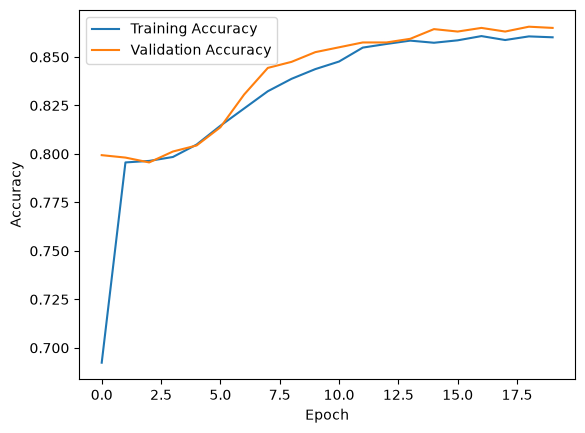

In [109]:
plt.plot(history.history["accuracy"], label = "Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

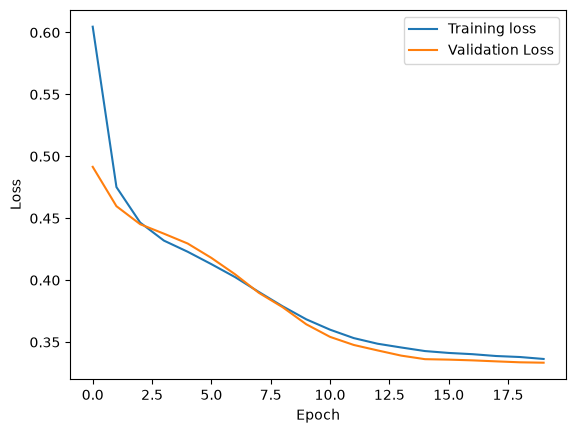

In [110]:
plt.plot(history.history["loss"], label = ["Training loss"])
plt.plot(history.history["val_loss"], label = ["Validation Loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [111]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print(class_weights)

{0: np.float64(0.6279434850863422), 1: np.float64(2.4539877300613497)}


In [112]:
model_weighted = Sequential([
    Dense(16, activation="relu", input_shape=(12,)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model_weighted.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_weighted = model_weighted.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights
)

Epoch 1/20


/Users/devanshithakur/Projects/customer-churn-ann/.venv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6108 - loss: 0.6376 - val_accuracy: 0.6956 - val_loss: 0.6151
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7133 - loss: 0.5837 - val_accuracy: 0.6938 - val_loss: 0.6107
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step - accuracy: 0.7163 - loss: 0.5610 - val_accuracy: 0.7181 - val_loss: 0.5649
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 847us/step - accuracy: 0.7223 - loss: 0.5425 - val_accuracy: 0.7350 - val_loss: 0.5255
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7381 - loss: 0.5262 - val_accuracy: 0.7406 - val_loss: 0.5174
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 835us/step - accuracy: 0.7470 - loss: 0.5125 - val_accuracy: 0.7656 - val_loss: 0.4829
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7613 - loss: 0.5008 - val_accuracy: 0.7544 - val_loss: 0.4915
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7659 - loss: 0.4903 - val_accuracy: 0.7644 

In [113]:
y_prob_weighted = model_weighted.predict(X_test_scaled)

y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred_weighted))
print(classification_report(y_test, y_pred_weighted))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 767us/step
[[1254  339]
 [  92  315]]
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      1593
           1       0.48      0.77      0.59       407

    accuracy                           0.78      2000
   macro avg       0.71      0.78      0.72      2000
weighted avg       0.84      0.78      0.80      2000



In [114]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Original ANN")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nWeighted ANN")
print("Accuracy:", accuracy_score(y_test, y_pred_weighted))
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall:", recall_score(y_test, y_pred_weighted))
print("F1 Score:", f1_score(y_test, y_pred_weighted))

Original ANN
Accuracy: 0.864
Precision: 0.7973568281938326
Recall: 0.44471744471744473
F1 Score: 0.5709779179810726

Weighted ANN
Accuracy: 0.7845
Precision: 0.481651376146789
Recall: 0.773955773955774
F1 Score: 0.5937794533459001


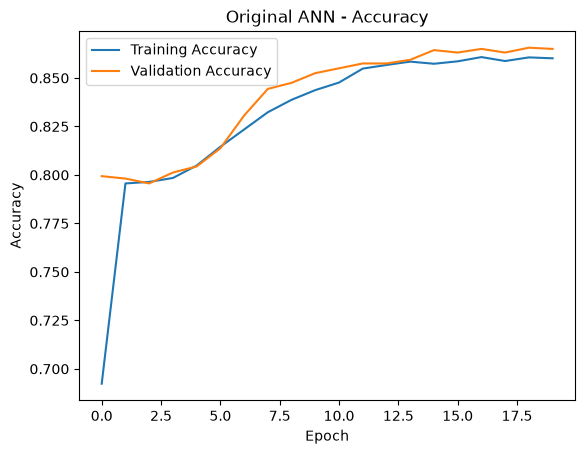

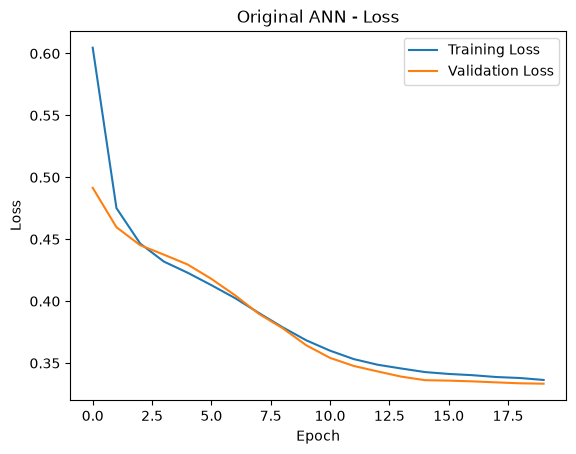

In [115]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Original ANN - Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Original ANN - Loss")
plt.legend()
plt.show()

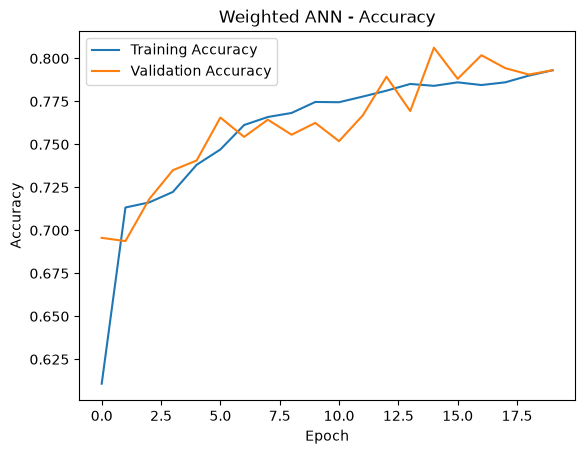

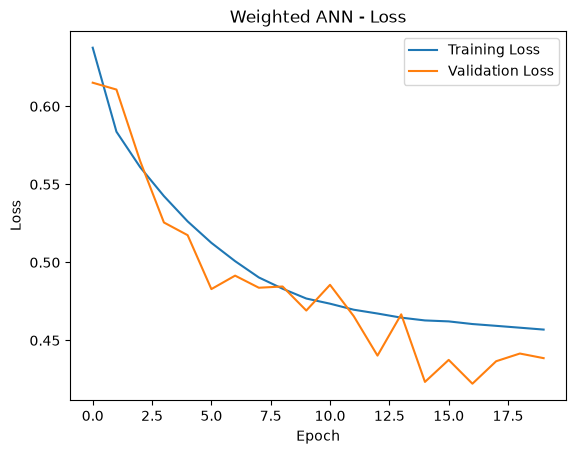

In [116]:
plt.plot(history_weighted.history["accuracy"], label="Training Accuracy")
plt.plot(history_weighted.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Weighted ANN - Accuracy")
plt.legend()
plt.show()

plt.plot(history_weighted.history["loss"], label="Training Loss")
plt.plot(history_weighted.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Weighted ANN - Loss")
plt.legend()
plt.show()

In [117]:
thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1:", f1_score(y_test, predictions))


Threshold: 0.3
Accuracy: 0.839
Precision: 0.5959367945823928
Recall: 0.6486486486486487
F1: 0.6211764705882353

Threshold: 0.4
Accuracy: 0.8585
Precision: 0.691358024691358
Recall: 0.5503685503685504
F1: 0.612859097127223

Threshold: 0.5
Accuracy: 0.864
Precision: 0.7973568281938326
Recall: 0.44471744471744473
F1: 0.5709779179810726

Threshold: 0.6
Accuracy: 0.854
Precision: 0.8362573099415205
Recall: 0.35135135135135137
F1: 0.49480968858131485


In [118]:
model.save("models/baseline_churn_ann.keras")
model_weighted.save("models/weighted_churn_ann.keras")

In [119]:
import joblib

joblib.dump(scaler, "models/scaler.pkl")

['models/scaler.pkl']

In [120]:
feature_names = X.columns.tolist()

print(feature_names)

joblib.dump(feature_names, "models/feature_names.pkl")

['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain']


['models/feature_names.pkl']

In [121]:
new_customer = pd.DataFrame({
    "CreditScore": [650],
    "Gender": [0],
    "Age": [42],
    "Tenure": [5],
    "Balance": [120000],
    "NumOfProducts": [2],
    "HasCrCard": [1],
    "IsActiveMember": [0],
    "EstimatedSalary": [80000],
    "Geography_France": [1],
    "Geography_Germany": [0],
    "Geography_Spain": [0]
})

In [122]:
new_customer = new_customer[feature_names]

In [123]:
new_customer_scaled = scaler.transform(new_customer)

In [124]:
probability = model_weighted.predict(new_customer_scaled)[0][0]

print("Churn probability:", probability)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Churn probability: 0.64636284


In [125]:
if probability >= 0.5:
    print("Prediction: Customer is likely to churn")
else:
    print("Prediction: Customer is likely to stay")

Prediction: Customer is likely to churn


In [126]:
from tensorflow.keras.models import load_model

loaded_model = load_model("models/weighted_churn_ann.keras")
loaded_scaler = joblib.load("models/scaler.pkl")
loaded_features = joblib.load("models/feature_names.pkl")

print("Model loaded successfully")
print("Number of features:", len(loaded_features))

Model loaded successfully
Number of features: 12
